In [8]:
pip install pandas scikit-learn nltk matplotlib seaborn

In [9]:
from google.colab import files

# Ceci va ouvrir une fenêtre pour sélectionner ton fichier
uploaded = files.upload()

Saving IMDB Dataset.csv to IMDB Dataset (1).csv


--- Aperçu des données ---
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

--- Informations sur le dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

--- Répartition des sentiments ---
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


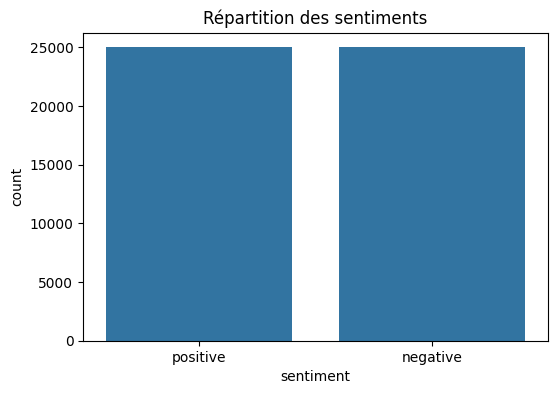

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le dataset
# Assure-toi que le fichier est dans le même dossier que ton script
df = pd.read_csv('IMDB Dataset.csv')

# Afficher les 5 premières lignes
print("--- Aperçu des données ---")
print(df.head())

# Afficher les informations générales (taille, types de données)
print("\n--- Informations sur le dataset ---")
df.info()

# Vérifier la répartition des sentiments (positif / négatif)
print("\n--- Répartition des sentiments ---")
print(df['sentiment'].value_counts())

# Visualiser la répartition
plt.figure(figsize=(6,4))
sns.countplot(x='sentiment', data=df)
plt.title('Répartition des sentiments')
plt.show()

In [11]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Télécharger les ressources NLTK nécessaires (à faire une seule fois)
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # 1. Supprimer les balises HTML
    text = re.sub(r'<.*?>', '', text)
    # 2. Supprimer les caractères non alphabétiques (garder les espaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # 3. Mettre en minuscules
    text = text.lower()
    # 4. Supprimer les stopwords et lemmatiser
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return ' '.join(words)

# Appliquer le nettoyage sur un échantillon pour voir le résultat
print("\n--- Avant / Après nettoyage ---")
print("AVANT :", df['review'][0][:200], "...")
df['cleaned_review'] = df['review'].apply(clean_text)
print("\nAPRÈS :", df['cleaned_review'][0][:200], "...")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!



--- Avant / Après nettoyage ---
AVANT : One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo ...

APRÈS : one reviewer mentioned watching oz episode youll hooked right exactly happened methe first thing struck oz brutality unflinching scene violence set right word go trust show faint hearted timid show pu ...


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialiser le vectorizer
# max_features=5000 limite le vocabulaire aux 5000 mots les plus fréquents
vectorizer = TfidfVectorizer(max_features=5000)

# Transformer le texte nettoyé en matrice TF-IDF
X = vectorizer.fit_transform(df['cleaned_review'])

# Transformer les labels (positive/negative) en 1/0
y = df['sentiment'].map({'positive': 1, 'negative': 0})

print("\n--- Forme de la matrice TF-IDF ---")
print(X.shape) # (nombre de documents, nombre de mots)


--- Forme de la matrice TF-IDF ---
(50000, 5000)



--- Évaluation du modèle ---
Accuracy : 0.8848

Rapport de classification :
              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      4961
    positive       0.88      0.90      0.89      5039

    accuracy                           0.88     10000
   macro avg       0.89      0.88      0.88     10000
weighted avg       0.89      0.88      0.88     10000



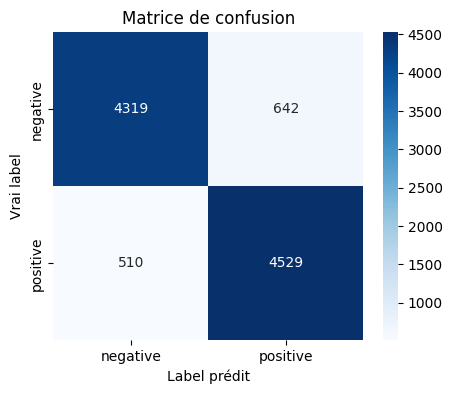

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialiser et entraîner le modèle
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Prédire sur l'ensemble de test
y_pred = model.predict(X_test)

# Évaluer
print("\n--- Évaluation du modèle ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred, target_names=['negative', 'positive']))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title('Matrice de confusion')
plt.ylabel('Vrai label')
plt.xlabel('Label prédit')
plt.show()

In [14]:
def predict_sentiment(review_text):
    # Nettoyer le texte
    cleaned = clean_text(review_text)
    # Vectoriser (attention : on utilise le même vectorizer que pour l'entraînement)
    vectorized = vectorizer.transform([cleaned])
    # Prédire
    prediction = model.predict(vectorized)[0]
    # Retourner le résultat
    return "POSITIF" if prediction == 1 else "NÉGATIF"

# Tester
print("\n--- Tests de prédiction ---")
test_reviews = [
    "This movie was absolutely fantastic, I loved every minute of it!",
    "What a terrible film, the acting was horrible and the plot made no sense.",
    "It was okay, not great but not bad either.",
    "A masterpiece of cinema, truly unforgettable."
]

for review in test_reviews:
    print(f"\nAvis : '{review}'")
    print(f"Prédiction : {predict_sentiment(review)}")


--- Tests de prédiction ---

Avis : 'This movie was absolutely fantastic, I loved every minute of it!'
Prédiction : POSITIF

Avis : 'What a terrible film, the acting was horrible and the plot made no sense.'
Prédiction : NÉGATIF

Avis : 'It was okay, not great but not bad either.'
Prédiction : NÉGATIF

Avis : 'A masterpiece of cinema, truly unforgettable.'
Prédiction : POSITIF


In [15]:
from sklearn.naive_bayes import MultinomialNB

# Entraîner un modèle Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Prédire et évaluer
y_pred_nb = nb_model.predict(X_test)
print("\n--- Évaluation du modèle Naive Bayes ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred_nb):.4f}")


--- Évaluation du modèle Naive Bayes ---
Accuracy : 0.8490
